# 01. 데이터 분석 · 전처리 · 기본 모델 (HIPE)

**목적:** 15분 평균 전력(최대수요전력 기준)을 구간이 끝나기 전에 더 정확히 예측할 수 있는지 확인한다.

**데이터 변경:** `mvlv-transformer.csv`(변압기 1대, 1초) → **HIPE** (독일 KIT 전자부품 공장, 2017-10-01 ~ 2017-12-31)
- 공장 전체(`MainTerminal`) + 장비 10대가 각각 따로 측정되어 있음 → 피크 때 어떤 장비가 전력을 쓰는지도 볼 수 있다

1. 원본 데이터 확인
2. 공장 전체 vs 장비별 전력
3. 전처리: 10초 평균, 규모 맞추기
4. 시간대별 부하 패턴
5. 15분 구간 평균 분포와 평가용 목표전력 (+ 피크 때 장비 구성)
6. 학습 샘플 만들기
7. 기존 계산식의 한계 확인
8. 기본 모델 (LightGBM 기본값) vs 기존 계산식
9. 정리

In [1]:
import os
import zipfile

import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 폰트 자동 설정
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor

plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["axes.unicode_minus"] = False

DATA_DIR = r"/home/gmlck/projects/power-edge/data"
ZIP_PATH = os.path.join(DATA_DIR, "01_원본", "hipe_cleaned_v1.0.1_geq_2017-10-01_lt_2018-01-01.zip")
WEEK_ZIP = os.path.join(DATA_DIR, "01_원본", "hipe_cleaned_v1.0.1_geq_2017-10-23_lt_2017-10-30.zip")
CACHE_PATH = os.path.join(DATA_DIR, "hipe_pkw_10s.pkl")   # 장비별 10초 평균 저장본

TZ = "Europe/Berlin"   # 시각, 요일은 현지 시간 기준으로 본다

## 1. 원본 데이터 확인

In [2]:
# zip 안 파일 목록: 장비 1대 = CSV 1개
zf = zipfile.ZipFile(ZIP_PATH)
files = pd.DataFrame(
    [(info.filename.split("_")[0], info.filename, info.file_size / 1e9) for info in zf.infolist()],
    columns=["machine", "file", "size_GB"],
)
print(f"파일 수: {len(files)}  /  압축 풀면 전체 {files['size_GB'].sum():.1f} GB")
files[["machine", "size_GB"]].round(2)

파일 수: 11  /  압축 풀면 전체 30.6 GB


,machine,size_GB
0,ChipPress,3.36
1,ChipSaw,3.40
2,HighTemperatureOven,3.62
3,MainTerminal,4.88
4,PickAndPlaceUnit,1.06
5,ScreenPrinter,0.90
6,SolderingOven,3.36
7,VacuumOven,3.27
8,VacuumPump1,2.46
9,VacuumPump2,0.75


In [3]:
# 컬럼 구성만 먼저 확인 (앞 5줄)
main_file = files.loc[files["machine"] == "MainTerminal", "file"].item()
head = pd.read_csv(zf.open(main_file), nrows=5)

print(f"컬럼 수: {head.shape[1]}")
print(head.columns[:40].tolist())
head[["SensorDateTime", "Machine", "P_kW", "Q_kvar", "S_kVA", "I1_A", "V1_V"]]

컬럼 수: 362
['SensorDateTime', 'Machine', 'PhaseCount', 'T_h', 'U12_V', 'U23_V', 'U31_V', 'V1_V', 'V2_V', 'V3_V', 'F_Hz', 'I1_A', 'I2_A', 'I3_A', 'IN_A', 'P_kW', 'Q_kvar', 'S_kVA', 'L_F', 'P1_kW', 'P2_kW', 'P3_kW', 'Q1_kvar', 'Q2_kvar', 'Q3_kvar', 'S1_kVA', 'S2_kVA', 'S3_kVA', 'L1_F', 'L2_F', 'L3_F', 'E_PP_kWh', 'E_QP_kvarh', 'E_SP_kVAh', 'E_PN_kWh', 'E_QN_kvarh', 'IAVR_A', 'UAVR_V', 'VAVR_V', 'THD_U12_F']


,SensorDateTime,Machine,P_kW,Q_kvar,S_kVA,I1_A,V1_V
0,2017-10-01T00:00:00.200+02,MainTerminal,6.38,2.27,6.77,13.812,238.300003
1,2017-10-01T00:00:05.773+02,MainTerminal,6.32,2.25,6.70,13.596,237.860001
2,2017-10-01T00:00:11.220+02,MainTerminal,6.27,2.23,6.65,13.488,237.750000
3,2017-10-01T00:00:16.703+02,MainTerminal,6.25,2.23,6.64,13.488,237.889999
4,2017-10-01T00:00:22.197+02,MainTerminal,6.27,2.24,6.66,13.476,237.860001


**확인할 것**
- 컬럼이 362개(전압, 전류, 고조파 등)인데 최대수요 예측에 필요한 건 **시각(`SensorDateTime`)과 유효전력(`P_kW`)** 뿐이다
- 전력 단위가 이미 kW (기존 CSV 는 W 라서 1000 으로 나눴었다)
- 시각 끝의 `+02` 는 시간대. 10/29 에 서머타임이 끝나서 `+01` 로 바뀐다

In [4]:
# 시간대가 바뀌는 날 확인: 앞 19글자만 자르면(기존 방식) 같은 시각이 두 번 생긴다
week = zipfile.ZipFile(WEEK_ZIP)
week_main = [n for n in week.namelist() if n.startswith("MainTerminal")][0]
w = pd.read_csv(week.open(week_main), usecols=["SensorDateTime", "P_kW"])

print(w["SensorDateTime"].str[-3:].value_counts())
naive = pd.to_datetime(w["SensorDateTime"].str[:19])
print("앞 19글자 방식 -> 시각이 거꾸로 가는 곳:", (naive.diff().dt.total_seconds() < 0).sum(), "군데")

SensorDateTime
+02    96054
+01    14438
Name: count, dtype: int64
앞 19글자 방식 -> 시각이 거꾸로 가는 곳: 1 군데


그래서 시각은 **UTC 로 읽고**(시간이 한 방향으로만 흐름), 시간대·요일 특징을 만들 때만 현지 시간으로 바꾼다.

In [5]:
# 장비별로 시각 + P_kW 만 읽기. CSV 가 커서(전체 30GB) 처음 한 번만 읽고 10초 평균으로 저장
def read_machine(name):
    d = pd.read_csv(zf.open(name), usecols=["SensorDateTime", "P_kW"], dtype={"P_kW": "float32"})
    d["ts"] = pd.to_datetime(d["SensorDateTime"], format="ISO8601", utc=True)
    s = d.set_index("ts")["P_kW"].sort_index()
    return s[~s.index.duplicated()]


if os.path.exists(CACHE_PATH):
    cache = pd.read_pickle(CACHE_PATH)
    machines, raw_info = cache["machines"], cache["raw_info"]
else:
    steps_list, info_rows = {}, []
    for _, row in files.iterrows():
        s = read_machine(row["file"])
        gap = s.index.to_series().diff().dt.total_seconds()
        info_rows.append({
            "machine": row["machine"], "rows": len(s),
            "start": s.index.min(), "end": s.index.max(),
            "gap_median_s": gap.median(), "gap_over_1m": (gap > 60).sum(), "gap_max_h": gap.max() / 3600,
            "kw_min": s.min(), "kw_max": s.max(), "neg_ratio": (s < 0).mean(),
        })
        steps_list[row["machine"]] = s.resample("10s").mean()
        print(f"{row['machine']:18s} {len(s):,}행")
    machines = pd.DataFrame(steps_list)
    raw_info = pd.DataFrame(info_rows).set_index("machine")
    pd.to_pickle({"machines": machines, "raw_info": raw_info}, CACHE_PATH)

print(f"기간(UTC): {raw_info['start'].min()} ~ {raw_info['end'].max()}")
raw_info.drop(columns=["start", "end"]).round(3)

기간(UTC): 2017-09-30 22:00:00.200000+00:00 ~ 2017-12-31 22:59:59.900000+00:00


,rows,gap_median_s,gap_over_1m,gap_max_h,kw_min,kw_max,neg_ratio
machine,,,,,,,
ChipPress,1450066,5.477,14,0.141,-0.00,28.430000,0.000
ChipSaw,1450066,5.480,13,0.143,0.00,0.980000,0.000
HighTemperatureOven,1450028,5.477,13,0.142,-0.21,13.020000,0.111
MainTerminal,1450300,5.477,9,0.143,3.72,77.389999,0.000
PickAndPlaceUnit,1611464,4.933,9,0.141,-0.01,0.460000,0.899
ScreenPrinter,1611194,4.930,11,0.143,0.00,0.480000,0.000
SolderingOven,1450296,5.477,8,0.141,-0.02,8.490000,0.000
VacuumOven,1434675,5.480,15,21.207,-0.01,5.710000,0.000
VacuumPump1,1450296,5.477,9,0.143,-0.00,1.080000,0.000


**확인할 것**
- 측정 간격 (기존 CSV 는 1초, HIPE 는 몇 초인지)
- 1분 넘게 끊긴 곳, 가장 긴 누락
- 음수 전력 비율 (측정 잡음)

**관찰**
- 측정 간격 약 5.5초 (일부 장비 4.9초). 기존 1초보다 5배 성김 → 10초 칸에 값이 1~2개
- 누락은 거의 없음. 1분 넘게 끊긴 곳이 장비당 10여 군데, 길어야 8~9분. 예외: `VacuumOven` 21시간 누락 1번
- `MainTerminal` 은 3.7 ~ 77 kW, 음수 없음. 장비들은 최대값이 1~28 kW 로 훨씬 작음
- `PickAndPlaceUnit` 은 90% 가 음수 (-0.01 수준). 측정 방향이 뒤집혔거나 대기전력 잡음으로 보임 → 값이 워낙 작아 0 으로 잘라도 영향 미미

## 2. 공장 전체 vs 장비별 전력

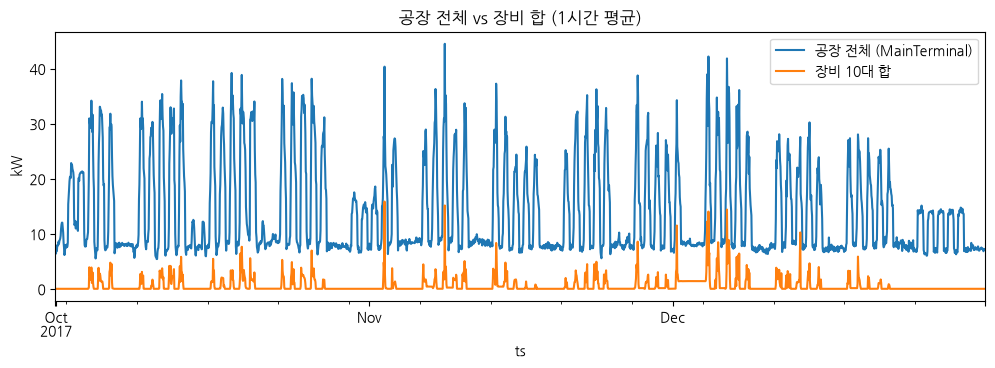

평균 전력  공장 전체: 14.0 kW  /  장비 10대 합: 0.57 kW
장비 합 / 공장 전체 (평균): 4.1%


In [6]:
main = machines["MainTerminal"]
parts = machines.drop(columns="MainTerminal")

# 장비 10대 합이 공장 전체와 얼마나 맞나 (1시간 평균으로 비교)
hourly_cmp = pd.DataFrame({
    "공장 전체 (MainTerminal)": main.resample("1h").mean(),
    "장비 10대 합": parts.clip(lower=0).sum(axis=1, min_count=1).resample("1h").mean(),
})
hourly_cmp.plot(title="공장 전체 vs 장비 합 (1시간 평균)", ylabel="kW")
plt.show()

print(f"평균 전력  공장 전체: {hourly_cmp.iloc[:, 0].mean():.1f} kW  /  장비 10대 합: {hourly_cmp.iloc[:, 1].mean():.2f} kW")
print(f"장비 합 / 공장 전체 (평균): {(hourly_cmp.iloc[:, 1].mean() / hourly_cmp.iloc[:, 0].mean()):.1%}")

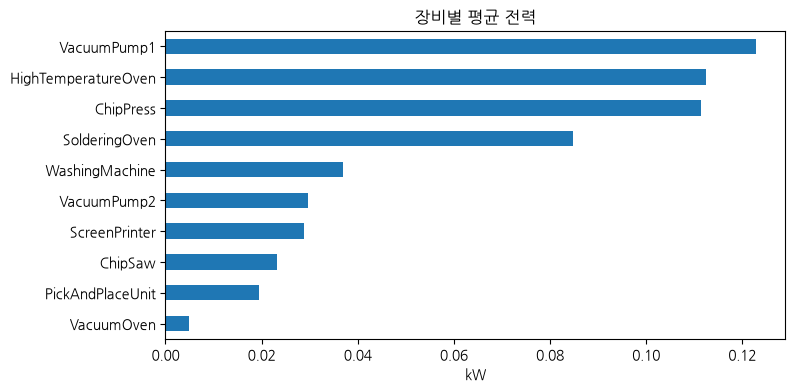

VacuumPump1            0.69
ScreenPrinter          0.51
ChipSaw                0.47
PickAndPlaceUnit       0.43
SolderingOven          0.33
HighTemperatureOven    0.33
VacuumPump2            0.32
ChipPress              0.19
WashingMachine         0.11
VacuumOven             0.11
dtype: float64

In [7]:
# 장비별 평균 전력 (가동 중 기준이 아니라 전체 평균)
parts.clip(lower=0).mean().sort_values().plot(kind="barh", title="장비별 평균 전력", xlabel="kW", figsize=(8, 4))
plt.show()

# 장비 전력이 공장 전체와 같이 움직이나 (10초 단위 상관계수)
parts.corrwith(main).sort_values(ascending=False).round(2)

**확인할 것**
- 장비 10대가 공장 전체 전력의 얼마를 설명하는지 (나머지는 조명, 공조 등 측정 안 된 부하)
- 전력을 주로 쓰는 장비가 무엇인지

**관찰**
- 장비 10대 합은 공장 전체의 **약 4%** 뿐이다. 공장 전력 대부분은 측정 안 된 부하(공조, 조명, 다른 설비)
- 장비들은 대부분 시간에 꺼져 있다 (중앙값 0). 켜질 때만 짧게 수 kW
- 그래도 공장 전체와 상관은 있음 (`VacuumPump1` 0.69 등) → 장비 전력이 "생산 중인가"를 알려주는 신호 역할은 할 수 있다
- 그래프에서 평일/주말 반복이 뚜렷하고, **12월 말(크리스마스 주)은 평일인데도 낮고 평평**하다

예측 대상은 기존처럼 **공장 전체 1개 계량기**(`MainTerminal`)로 둔다. 실제 최대수요전력은 수전 계량기 하나로 정해지기 때문.

## 3. 전처리

1. **10초 평균**: 기존과 같이 10초 = 1칸 (`features.py` 와 맞춤). HIPE 는 측정 간격이 더 길어서 한 칸에 보통 1~2개 값이 들어간다.
2. **음수는 0 으로** (측정 잡음)
3. **규모 맞추기**: 시뮬레이터 규모(1,400kW급)로 키운다. 정지 시간을 빼고, 가동 중 상위 5% 값이 1,400kW 가 되도록 배율을 곱한다.

In [8]:
steps = main.clip(lower=0)

print("원래 규모")
print(steps.describe().round(1))

# 공장 정지(최대값의 5% 이하)를 뺀 가동 중 전력
running = steps[steps > steps.max() * 0.05]
scale = 1400 / running.quantile(0.95)
steps = steps * scale

print()
print(f"10초 칸 수 : {len(steps):,}")
print(f"빈 칸 비율 : {steps.isna().mean():.2%}")
print(f"규모 배율  : x{scale:.1f}")
print(f"가장 낮은 전력(배율 후): {steps.min():,.0f} kW  ->  공장이 완전히 멈추는 때가 없다")

원래 규모
count    795109.0
mean         14.0
std           9.0
min           3.7
25%           6.0
50%          11.7
75%          19.6
max          76.9
Name: MainTerminal, dtype: float64

10초 칸 수 : 795,240
빈 칸 비율 : 0.02%
규모 배율  : x44.3
가장 낮은 전력(배율 후): 165 kW  ->  공장이 완전히 멈추는 때가 없다


빈 칸이 있는 15분 구간은 정답(실제 평균)을 알 수 없으므로 뒤에서 학습에서 뺀다.

## 4. 시간대별 부하 패턴

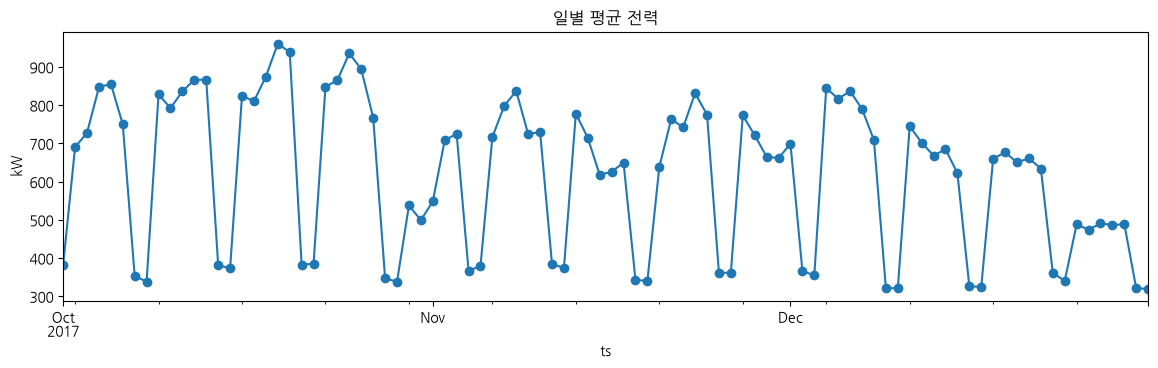

평균이 가장 낮은 평일
ts
2017-12-26    474.0
2017-12-28    486.0
2017-12-25    488.0
2017-12-29    489.0
2017-12-27    491.0
2017-10-31    499.0
2017-10-30    538.0
2017-11-01    548.0
Name: MainTerminal, dtype: float32


In [9]:
local = steps.tz_convert(TZ)   # 그래프, 시간대 집계는 현지 시간

# 전체 기간 일별 평균: 휴일, 장기 정지 확인
daily = local.resample("1D").mean()
daily.index = daily.index.tz_localize(None)
daily.plot(marker="o", title="일별 평균 전력", ylabel="kW", figsize=(14, 3.5))
plt.show()

print("평균이 가장 낮은 평일")
print(daily[daily.index.dayofweek < 5].nsmallest(8).round(0))

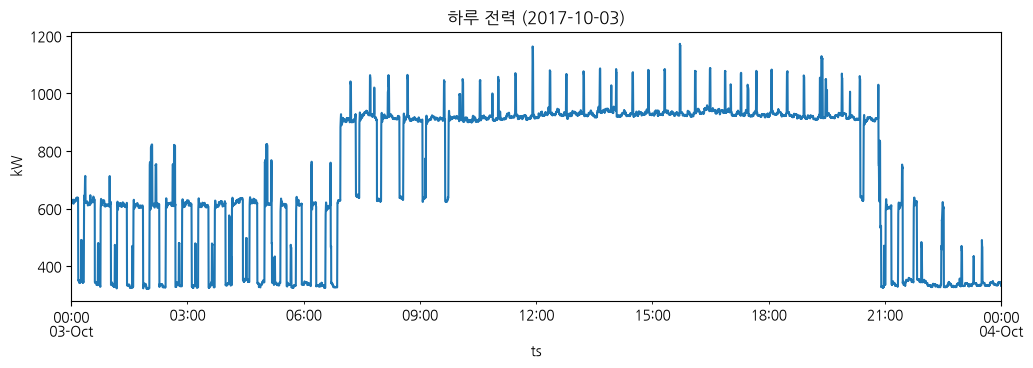

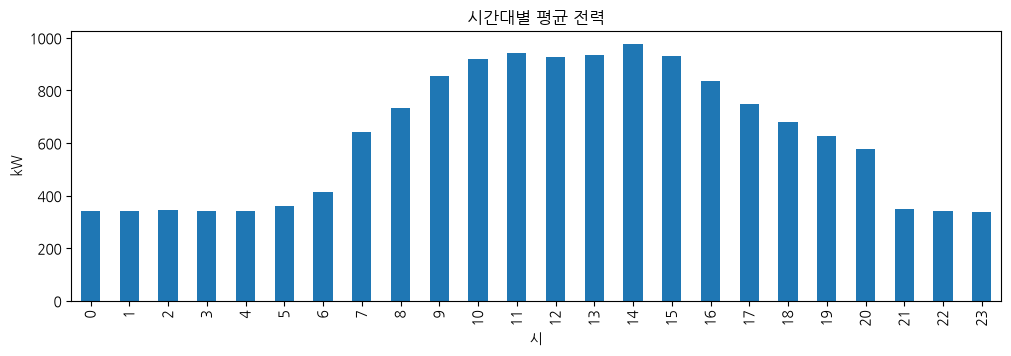

In [10]:
# 하루 예시 (평일 하루)
days = local.index.normalize().unique()
day = days[2]   # 2017-10-03 (화, 독일 공휴일인데 정상 가동)
local[day:day + pd.Timedelta(days=1)].plot(title=f"하루 전력 ({day:%Y-%m-%d})", ylabel="kW")
plt.show()

# 시간대별 평균
hourly = local.groupby(local.index.hour).mean()
hourly.plot(kind="bar", title="시간대별 평균 전력", xlabel="시", ylabel="kW")
plt.show()

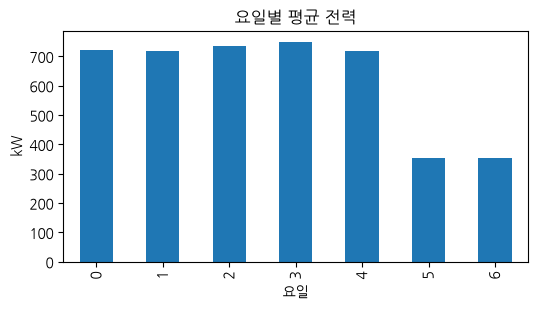

In [11]:
# 요일별 평균 (0=월 ... 6=일)
weekday = local.groupby(local.index.dayofweek).mean()
weekday.plot(kind="bar", title="요일별 평균 전력", xlabel="요일", ylabel="kW", figsize=(6, 3))
plt.show()

In [12]:
# 기존 데이터와 비교: 10초 사이 출렁임이 얼마나 큰가
jump = steps.diff().abs()
print(f"10초 변화량 중앙값: {jump.median():.1f} kW  /  상위 1%: {jump.quantile(0.99):.1f} kW")

10초 변화량 중앙값: 1.3 kW  /  상위 1%: 204.9 kW


**확인할 것:** 가동 / 정지 시간대, 요일별 차이, 하루 안에서 부하가 얼마나 출렁이는지.

**관찰**
- 하루 모양: 밤 ~340kW(기저부하) → 7시 급증 → 10~15시 900kW 대 → 21시 급감. 14시가 가장 높음
- 밤에도 340 ↔ 620kW 를 왔다갔다 하는 큰 설비가 있다 (켜졌다 꺼졌다 반복)
- 낮에는 수십 초짜리 +100~200kW 순간 튐이 자주 있다 (10초 변화량 상위 1% ≈ 205kW). 지금 전력이 끝까지 간다고 가정하는 기존 계산식이 이 튐에 흔들린다
- 토·일은 평일의 절반 (기저부하 수준만)
- 평균이 가장 낮은 평일은 12/25~29 (크리스마스 주)와 10/30~11/1 (종교개혁일·만성절 연휴). 평일 달력만으로는 쉬는 날을 다 알 수 없다
- **크리스마스 주가 시험 데이터에 들어간다** (아래 분할에서 확인)

## 5. 15분 구간 평균 분포

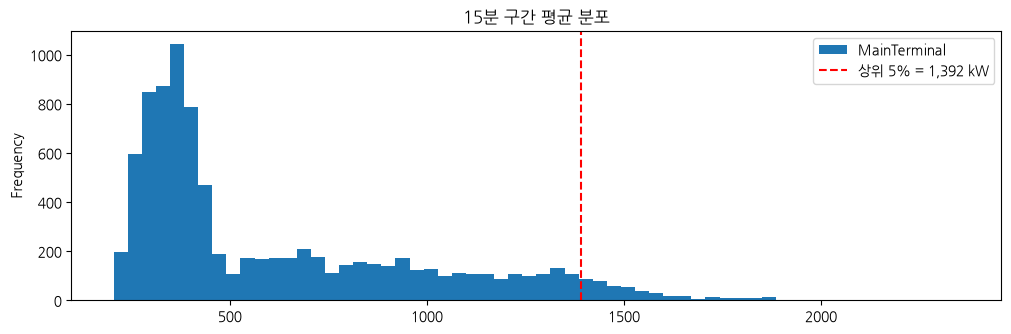

15분 구간 수: 8,836
평가용 목표전력(상위 5%): 1,392 kW


In [13]:
win = steps.resample("15min").mean().dropna()
target_kw = win.quantile(0.95)

win.plot(kind="hist", bins=60, title="15분 구간 평균 분포")
plt.axvline(target_kw, color="red", linestyle="--", label=f"상위 5% = {target_kw:,.0f} kW")
plt.legend()
plt.show()

print(f"15분 구간 수: {len(win):,}")
print(f"평가용 목표전력(상위 5%): {target_kw:,.0f} kW")

기존과 같이 **15분 평균 상위 5%**를 목표전력으로 둔다.
그래야 "막아야 할 피크" 구간이 생겨 놓친 피크·헛경보를 셀 수 있다.

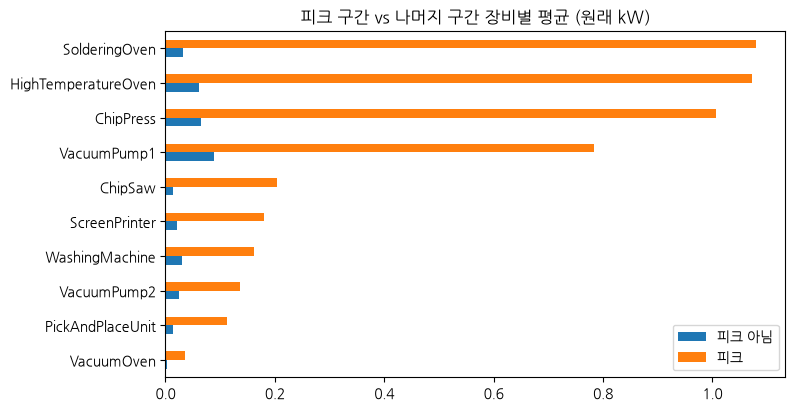

,피크 아님,피크,증가 (kW)
SolderingOven,0.03,1.08,1.05
HighTemperatureOven,0.06,1.07,1.01
ChipPress,0.06,1.01,0.94
VacuumPump1,0.09,0.78,0.69
ChipSaw,0.01,0.20,0.19
ScreenPrinter,0.02,0.18,0.16
WashingMachine,0.03,0.16,0.13
VacuumPump2,0.02,0.14,0.11
PickAndPlaceUnit,0.01,0.11,0.10
VacuumOven,0.00,0.04,0.03


In [14]:
# 피크 구간에는 어떤 장비가 돌고 있나: 피크(상위 5%) 구간 vs 평소 가동 구간의 장비별 평균
parts_win = parts.clip(lower=0).resample("15min").mean().loc[win.index]
is_peak = win > target_kw

by_state = pd.DataFrame({
    "피크 아님": parts_win[~is_peak].mean(),
    "피크": parts_win[is_peak].mean(),
})
by_state["증가 (kW)"] = by_state["피크"] - by_state["피크 아님"]
by_state.sort_values("증가 (kW)").plot(kind="barh", y=["피크 아님", "피크"],
                                      title="피크 구간 vs 나머지 구간 장비별 평균 (원래 kW)", figsize=(8, 4.5))
plt.show()
by_state.sort_values("증가 (kW)", ascending=False).round(2)

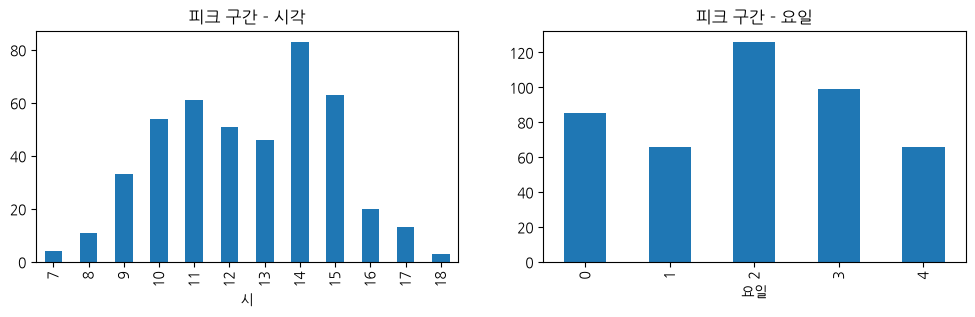

In [15]:
# 피크 구간은 언제 생기나 (현지 시간)
peak_local = win[is_peak].tz_convert(TZ).index
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
pd.Series(peak_local.hour).value_counts().sort_index().plot(kind="bar", ax=ax[0], title="피크 구간 - 시각", xlabel="시")
pd.Series(peak_local.dayofweek).value_counts().sort_index().plot(kind="bar", ax=ax[1], title="피크 구간 - 요일", xlabel="요일")
plt.show()

**확인할 것:** 피크를 만드는 장비, 피크가 몰리는 시간대.
특정 장비가 피크를 주도한다면 나중에 장비별 전력을 특징으로 넣는 것도 고려할 수 있다 (실제 현장에 장비별 계량기가 있다는 전제).

**관찰**
- 15분 평균 분포가 두 덩어리: 300~400kW (밤·주말 기저부하) 와 500~1,900kW 의 긴 꼬리 (낮 가동)
- 피크(상위 5%)는 **평일 7~18시에만**, 특히 10~15시. 주말 피크 0건
- 피크 때 장비 전력은 `SolderingOven`, `HighTemperatureOven`, `ChipPress`, `VacuumPump1` 순으로 늘지만 합쳐도 원래 단위로 ~4kW. 공장 피크(원래 단위 ~31kW)를 설명하기엔 작다 → 장비 데이터는 "보조 신호" 정도

## 6. 학습 샘플 만들기

**상황:** 15분 구간이 진행되는 도중(예: 5분 지난 시점)에 "이번 구간 평균이 얼마가 될지" 예측한다.

- 샘플 1개 = 한 구간 안의 한 예측 시점. 구간 시작 2분 후 ~ 14분까지 **1분 간격**
- 입력 = 예측 시점 **이전**의 데이터로만 만든 값 (미래 값을 쓰면 안 됨)
- 정답 `actual_kw` = 그 구간의 실제 15분 평균

**기존 계산식** `proj_base`: 지금까지 쓴 양 + "지금 전력이 구간 끝까지 그대로 간다"고 가정한 양

$$\text{proj\_base} = \frac{\text{지금까지 합} + \text{지금 전력} \times \text{남은 칸 수}}{90}$$

(15분 = 10초 × 90칸)

In [16]:
df = steps.to_frame("kw")

# 각 칸이 어느 15분 구간에 속하고, 구간 시작 후 몇 번째 칸인지 (UTC 기준이라 서머타임 영향 없음)
df["window_start"] = df.index.floor("15min")
df["k"] = (df.index.to_series() - df["window_start"]).dt.total_seconds() // 10   # 0 ~ 89
df["k"] = df["k"].astype(int)

df.head()

,kw,window_start,k
ts,,,
2017-09-30 22:00:00+00:00,281.373627,2017-09-30 22:00:00+00:00,0
2017-09-30 22:00:10+00:00,277.385651,2017-09-30 22:00:00+00:00,1
2017-09-30 22:00:20+00:00,277.385651,2017-09-30 22:00:00+00:00,2
2017-09-30 22:00:30+00:00,279.158081,2017-09-30 22:00:00+00:00,3
2017-09-30 22:00:40+00:00,279.158081,2017-09-30 22:00:00+00:00,4


In [17]:
# 정답: 구간 실제 평균. 구간 90칸이 모두 있어야 사용
win_mean = df.groupby("window_start")["kw"].mean()
win_count = df.groupby("window_start")["kw"].count()   # count 는 NaN 을 세지 않음
df["actual_kw"] = df["window_start"].map(win_mean)
df["full_window"] = df["window_start"].map(win_count) == 90

print(f"전체 구간: {len(win_count):,}  /  빠짐없는 구간: {(win_count == 90).sum():,}")

전체 구간: 8,836  /  빠짐없는 구간: 8,817


In [18]:
# 예측 시점 '직전'까지의 데이터만 쓰기 위해 한 칸 밀기(shift)
prev = df["kw"].shift(1)

# 현재 상태
df["kw_now"] = prev                                   # 직전 10초 전력
df["mean_1m"] = prev.rolling(6).mean()                # 최근 1분 평균
df["mean_5m"] = prev.rolling(30).mean()               # 최근 5분 평균
df["mean_10m"] = prev.rolling(60).mean()              # 최근 10분 평균
df["std_5m"] = prev.rolling(30).std()                 # 최근 5분 출렁임
df["max_10m"] = prev.rolling(60).max()
df["min_10m"] = prev.rolling(60).min()

# 기울기: 최근 1분 평균이 4분 전보다 얼마나 변했는지 (1칸당 kW)
df["slope"] = (df["mean_1m"] - df["mean_1m"].shift(24)) / 24

# 이번 구간에서 지금까지 쓴 양 (현재 칸 제외한 누적합)
df["used_sum"] = df.groupby("window_start")["kw"].cumsum() - df["kw"]
df["elapsed_ratio"] = df["k"] / 90

# 시간 정보 (현지 시간)
local_idx = df.index.tz_convert(TZ)
df["hour"] = local_idx.hour
df["dow"] = local_idx.dayofweek

In [19]:
remain = 90 - df["k"]   # 남은 칸 수

# 기준 1: 기존 계산식 (지금 전력 유지)
df["proj_base"] = (df["used_sum"] + df["kw_now"] * remain) / 90

# 기준 2: 추세 보정 (지금 기울기대로 계속 오르내린다고 가정, 음수는 0)
future = (df["kw_now"] * remain + 0.5 * df["slope"] * remain ** 2).clip(lower=0)
df["proj_trend"] = (df["used_sum"] + future) / 90

In [20]:
# 예측 시점만 남기기: 구간 시작 2분(12칸) ~ 14분(84칸), 1분(6칸) 간격
points = df[df["k"].isin(range(12, 85, 6)) & df["full_window"]].copy()
points["elapsed_min"] = points["k"] / 6

FEATURES = [
    "elapsed_ratio", "kw_now", "proj_base", "proj_trend",
    "mean_1m", "mean_5m", "mean_10m", "std_5m", "slope", "max_10m", "min_10m",
    "hour", "dow",
]

# 최근 10분 안에 빈 칸이 있으면 특징이 NaN -> 제외
points = points.dropna(subset=FEATURES)

# 모델이 맞힐 값: 실제 평균 - 기존 계산식 (계산식이 얼마나 틀리는지)
points["residual"] = points["actual_kw"] - points["proj_base"]

print(f"샘플 수: {len(points):,}")
points[["window_start", "elapsed_min", "kw_now", "proj_base", "proj_trend", "actual_kw", "residual"]].head(10)

샘플 수: 114,584


,window_start,elapsed_min,kw_now,proj_base,proj_trend,actual_kw,residual
ts,,,,,,,
2017-09-30 22:10:00+00:00,2017-09-30 22:00:00+00:00,10.0,295.774628,291.085076,294.608398,297.123657,6.038582
2017-09-30 22:11:00+00:00,2017-09-30 22:00:00+00:00,11.0,418.737152,329.322854,341.099684,297.123657,-32.199197
2017-09-30 22:12:00+00:00,2017-09-30 22:00:00+00:00,12.0,281.816711,296.968572,300.577135,297.123657,0.155085
2017-09-30 22:13:00+00:00,2017-09-30 22:00:00+00:00,13.0,284.032257,297.362439,297.058418,297.123657,-0.238782
2017-09-30 22:14:00+00:00,2017-09-30 22:00:00+00:00,14.0,280.930511,297.047342,296.948874,297.123657,0.076315
2017-09-30 22:17:00+00:00,2017-09-30 22:15:00+00:00,2.0,281.816711,281.784713,279.652564,289.014771,7.230058
2017-09-30 22:18:00+00:00,2017-09-30 22:15:00+00:00,3.0,280.487396,280.664640,278.936509,289.014771,8.350130
2017-09-30 22:19:00+00:00,2017-09-30 22:15:00+00:00,4.0,282.702942,282.407537,282.593707,289.014771,6.607233
2017-09-30 22:20:00+00:00,2017-09-30 22:15:00+00:00,5.0,290.457336,287.975920,294.068657,289.014771,1.038851


**데이터 나누기**

1주 파일(`2017-10-23 ~ 10-30`)은 별도 테스트 데이터가 아니라 **3개월 데이터 안에 들어 있는 같은 기간의 샘플**이다 (아래에서 확인).
그래서 따로 쓰지 않고, 3개월을 날짜 순으로 나눈다.

In [21]:
# 1주 파일이 3개월 데이터와 같은 값인지 확인
w_ts = pd.to_datetime(w["SensorDateTime"], format="ISO8601", utc=True)
w_kw = pd.Series(w["P_kW"].to_numpy(), index=w_ts).resample("10s").mean()
overlap = pd.concat([w_kw, main], axis=1, join="inner").dropna()
print(f"1주 파일 기간: {w_ts.min()} ~ {w_ts.max()}")
print(f"3개월과 겹치는 칸: {len(overlap):,}  /  값 차이 최대: {(overlap.iloc[:, 0] - overlap.iloc[:, 1]).abs().max():.4f} kW")

1주 파일 기간: 2017-10-22 22:00:03.727000+00:00 ~ 2017-10-29 22:59:57.667000+00:00
3개월과 겹치는 칸: 60,831  /  값 차이 최대: 0.0000 kW


In [22]:
# 날짜 기준 분할: 앞 70% 학습 / 다음 15% 검증 / 마지막 15% 시험
# 랜덤으로 섞으면 같은 구간이 학습·시험에 동시에 들어가 성능이 부풀려진다
day_of_point = points.index.tz_convert(TZ).normalize()
dates = sorted(day_of_point.unique())
n_train = int(len(dates) * 0.70)
n_valid = int(len(dates) * 0.15)

train_dates = dates[:n_train]
valid_dates = dates[n_train:n_train + n_valid]

points["split"] = "test"
points.loc[day_of_point.isin(train_dates), "split"] = "train"
points.loc[day_of_point.isin(valid_dates), "split"] = "valid"

for name in ["train", "valid", "test"]:
    part = points[points["split"] == name]
    d = day_of_point[points["split"] == name]
    peak_ratio = (part["actual_kw"] > target_kw).mean()
    print(f"{name:5s} {d.min():%m-%d} ~ {d.max():%m-%d}  {len(part):,}개  피크 비율 {peak_ratio:.1%}")

train 10-01 ~ 12-03  79,775개  피크 비율 6.1%
valid 12-04 ~ 12-16  16,149개  피크 비율 5.1%
test  12-17 ~ 12-31  18,660개  피크 비율 0.1%


**관찰:** 시험 기간(12/17~31)의 피크 비율이 **0.1%** — 크리스마스 연휴 때문에 피크가 거의 없다.
시험 MAE 가 낮게 나와도 "쉬운 기간"이라서일 수 있고, 피크 판단(놓친 피크·헛경보)은 시험 기간으로는 평가 자체가 안 된다.
→ 이 노트북에서는 모델 비교를 **valid 위주**로 보고, test 는 참고만 한다.

## 7. 기존 계산식의 한계

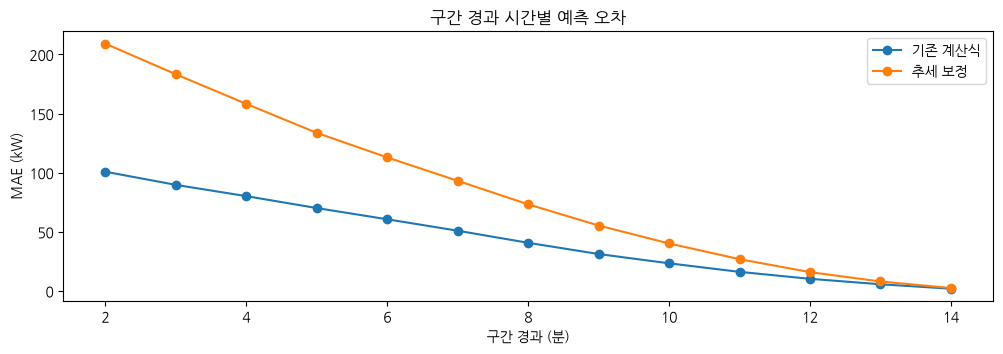

elapsed_min,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0
기존 계산식,100.9,89.8,80.2,70.1,60.6,51.0,40.8,31.3,23.4,16.2,10.3,5.7,2.0
추세 보정,209.1,183.3,158.2,133.7,112.9,93.2,73.3,55.4,40.2,26.9,16.0,8.0,2.5


In [23]:
points["err_base"] = (points["proj_base"] - points["actual_kw"]).abs()
points["err_trend"] = (points["proj_trend"] - points["actual_kw"]).abs()

by_min = points.groupby("elapsed_min")[["err_base", "err_trend"]].mean()
by_min.columns = ["기존 계산식", "추세 보정"]

by_min.plot(marker="o", title="구간 경과 시간별 예측 오차", xlabel="구간 경과 (분)", ylabel="MAE (kW)")
plt.show()
by_min.round(1).T

**확인할 것:** 구간 초반일수록 오차가 큰지. 남은 시간이 길수록 "지금 전력이 끝까지 간다"는 가정이 많이 틀린다.

**관찰**
- 기존 계산식: 2분 시점 ~100kW → 14분 시점 2kW. 초반 오차가 크다 (기존 데이터와 같은 경향)
- 추세 보정은 모든 시점에서 기존 계산식보다 **나쁘다** (2분 시점 2배). 순간 튐이 잦아서 기울기를 그대로 연장하면 크게 빗나간다

## 8. 기본 모델 (LightGBM 기본값)

정답을 직접 맞히지 않고 **잔차(실제 − 기존 계산식)**를 맞힌다. 최종 예측 = 기존 계산식 + 모델이 예측한 잔차.

In [24]:
train = points[points["split"] == "train"]
valid = points[points["split"] == "valid"]
test = points[points["split"] == "test"]

model = LGBMRegressor(random_state=42, verbose=-1)
model.fit(train[FEATURES], train["residual"])

valid_pred = valid["proj_base"] + model.predict(valid[FEATURES])
test_pred = test["proj_base"] + model.predict(test[FEATURES])


def mae(pred, actual):
    return (pred - actual).abs().mean()


compare = pd.DataFrame({
    "기존 계산식": [mae(valid["proj_base"], valid["actual_kw"]), mae(test["proj_base"], test["actual_kw"])],
    "추세 보정": [mae(valid["proj_trend"], valid["actual_kw"]), mae(test["proj_trend"], test["actual_kw"])],
    "LightGBM 기본값": [mae(valid_pred, valid["actual_kw"]), mae(test_pred, test["actual_kw"])],
}, index=["valid MAE (kW)", "test MAE (kW)"])
compare.round(1)

,기존 계산식,추세 보정,LightGBM 기본값
valid MAE (kW),51.2,99.1,33.8
test MAE (kW),47.6,89.8,27.4


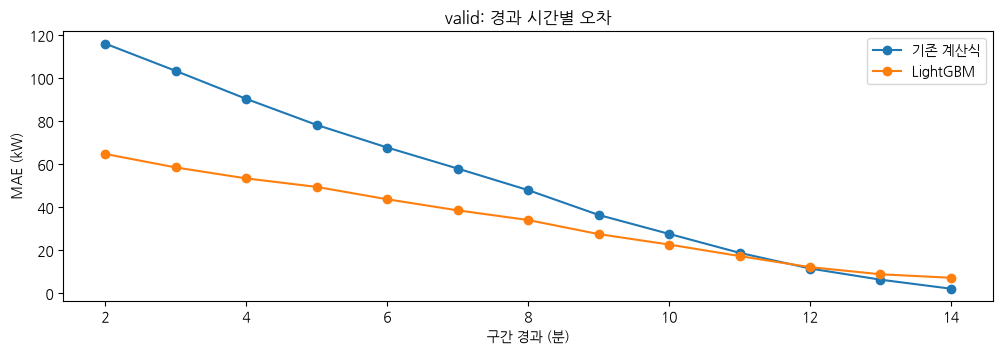

In [25]:
# 경과 시간별 비교 (valid)
valid_err = pd.DataFrame({
    "기존 계산식": (valid["proj_base"] - valid["actual_kw"]).abs(),
    "LightGBM": (valid_pred - valid["actual_kw"]).abs(),
    "elapsed_min": valid["elapsed_min"],
}).groupby("elapsed_min").mean()

valid_err.plot(marker="o", title="valid: 경과 시간별 오차", xlabel="구간 경과 (분)", ylabel="MAE (kW)")
plt.show()

In [26]:
# 피크 판단: 목표전력을 넘을지 맞혔는가 (valid)
actual_peak = valid["actual_kw"] > target_kw

summary = {}
for name, pred in [("기존 계산식", valid["proj_base"]), ("LightGBM", valid_pred)]:
    pred_peak = pred > target_kw
    summary[name] = {
        "실제 피크 시점 수": actual_peak.sum(),
        "놓친 피크": (actual_peak & ~pred_peak).sum(),
        "헛경보": (~actual_peak & pred_peak).sum(),
    }

pd.DataFrame(summary)

,기존 계산식,LightGBM
실제 피크 시점 수,819,819
놓친 피크,102,108
헛경보,146,107


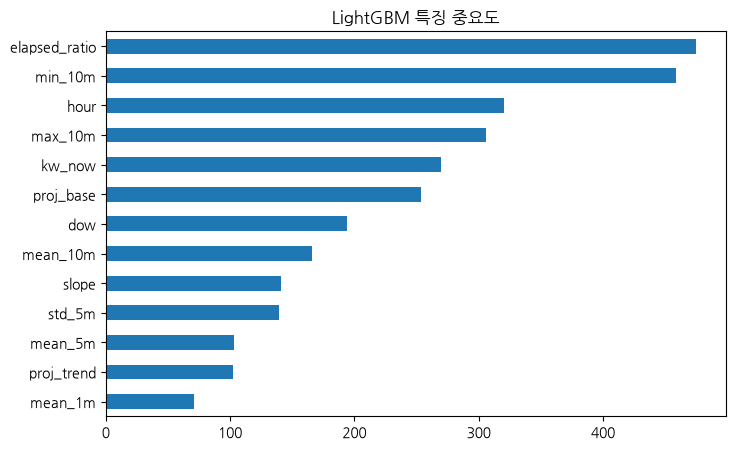

In [27]:
# 어떤 특징이 중요했나 (나눠진 횟수 기준)
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
importance.plot(kind="barh", title="LightGBM 특징 중요도", figsize=(8, 5))
plt.show()

**관찰**
- LightGBM 기본값이 MAE 를 valid 51 → 34kW, test 48 → 27kW 로 줄였다 (약 1/3 감소)
- 개선은 **구간 초반(2~8분)에 집중**. 12분 이후에는 오히려 기존 계산식이 더 정확하다 (14분: 2kW vs 7kW)
  → 남은 시간이 짧으면 계산식이 거의 정답인데, 모델이 잔차를 괜히 보정해서 오차를 더함
- 피크 판단: 헛경보 146 → 107 로 줄었지만 놓친 피크는 102 → 108 로 조금 늘었다. MAE 만 보고 좋아졌다고 하기 어렵다
- 중요도 상위: `elapsed_ratio`, `min_10m`, `hour`, `max_10m`. 최근 10분 최저/최고값(= 순간 튐 범위)과 시각이 중요

## 9. 정리

- **데이터:** HIPE 공장 전체(`MainTerminal`) 3개월, 5.5초 간격, 누락 거의 없음. 1주 파일은 같은 기간 샘플이라 따로 쓰지 않음
- **부하 특성:** 기저부하 ~340kW 가 항상 있고, 평일 낮에만 900kW 대로 오름. 피크는 평일 10~15시. 낮에 짧은 순간 튐이 잦음
- **장비별 데이터:** 장비 10대 합이 공장의 ~4% 라 피크 원인 설명은 약함. 가동 여부 신호로는 활용 여지
- **기존 계산식 한계:** 구간 초반 오차가 큼. 추세 보정은 순간 튐 때문에 오히려 나빠짐
- **기본 모델:** MAE 1/3 감소, 하지만 구간 후반엔 계산식보다 나쁘고 놓친 피크는 줄지 않음
- **다음 단계**
  - 구간 후반엔 계산식 쓰기 / 경과 시간에 따라 섞기
  - 놓친 피크를 줄이는 쪽으로 평가·손실 조정 (피크 구간 가중치 등)
  - 하이퍼파라미터 튜닝, 다른 모델 비교
  - 시험 기간에 피크가 거의 없음 (0.1%) → 분할 방식 재검토 (예: 연휴 제외, 또는 주 단위 교차검증)